# MANUAL NET ARCHITECTURE

In [1]:
import warnings
warnings.filterwarnings('ignore')

In [2]:
import os
import glob
import numpy as np

from tensorflow.keras.preprocessing.image import ImageDataGenerator

from tensorflow.keras.models import Sequential
from PIL import Image

from tensorflow.keras.layers import Convolution2D
from tensorflow.keras.layers import MaxPooling2D
from tensorflow.keras.layers import Flatten
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Activation

from keras.callbacks import ModelCheckpoint
import matplotlib.pyplot as plt

In [3]:
Abnormal_heart_beats = 'DATASET/TRAIN/Abnormal heart beats'
Cardiomyopathy = 'DATASET/TRAIN/Cardiomyopathy'
COVID_19 = 'DATASET/TRAIN/COVID-19'
Myocardial_Infarction = 'DATASET/TRAIN/Myocardial Infarction'
Normal = 'DATASET/TRAIN/Normal'

In [4]:
def plot_images(item_dir, n=6):
    all_item_dir = os.listdir(item_dir)
    item_files = [os.path.join(item_dir, file) for file in all_item_dir][:n]
    
    plt.figure(figsize=(80, 40))
    for idx, img_path in enumerate(item_files):
        plt.subplot(3, n, idx+1)
        img = plt.imread(img_path)
        plt.imshow(img, cmap='gray')
        plt.axis('off')
    
    plt.tight_layout()
    
def image_details_print(data,path):
    print('======== Images in: ', path)
    for key,values in data.items():
        print(key,':\t', values)


def images_details(path):
    files=[f for f in glob.glob(path + "**/*.*", recursive=True)]
    data={}
    data['Images_count']=len(files)
    data['Min_width']=10**100
    data['Max_width']=0
    data['Min_height']=10**100
    data['Max_height']=0
    
    for f in files:
        img=Image.open(f)
        width,height=img.size
        data['Min_width']=min(width,data['Min_width'])
        data['Max_width']=max(width, data['Max_width'])
        data['Min_height']=min(height, data['Min_height'])
        data['Max_height']=max(height, data['Max_height'])
        
    image_details_print(data,path)


TRAINING DATA FOR Abnormal_heart_beats:

======== Images in:  DATASET/TRAIN/Abnormal heart beats
Images_count :	 1000
Min_width :	 2213
Max_width :	 2213
Min_height :	 1572
Max_height :	 1572



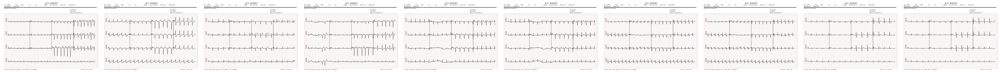

In [5]:
print("")
print("TRAINING DATA FOR Abnormal_heart_beats:")
print("")
images_details(Abnormal_heart_beats)
print("")
plot_images(Abnormal_heart_beats, 10) 


TRAINING DATA FOR Cardiomyopathy:

======== Images in:  DATASET/TRAIN/Cardiomyopathy
Images_count :	 1000
Min_width :	 2213
Max_width :	 2213
Min_height :	 1572
Max_height :	 1572



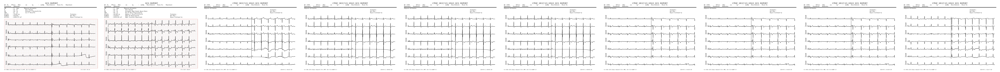

In [6]:
print("")
print("TRAINING DATA FOR Cardiomyopathy:")
print("")
images_details(Cardiomyopathy)
print("")
plot_images(Cardiomyopathy, 10)


TRAINING DATA FOR COVID_19:

======== Images in:  DATASET/TRAIN/COVID-19
Images_count :	 1000
Min_width :	 876
Max_width :	 2213
Min_height :	 859
Max_height :	 1572



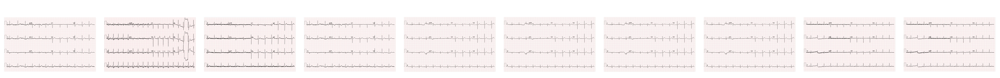

In [7]:
print("")
print("TRAINING DATA FOR COVID_19:")
print("")
images_details(COVID_19)
print("")
plot_images(COVID_19, 10)


TRAINING DATA FOR Myocardial_Infarction:

======== Images in:  DATASET/TRAIN/Myocardial Infarction
Images_count :	 1000
Min_width :	 2213
Max_width :	 2213
Min_height :	 1572
Max_height :	 1572



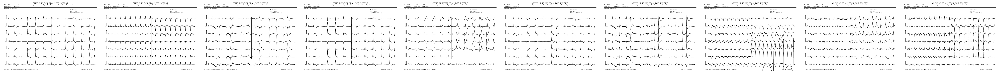

In [8]:
print("")
print("TRAINING DATA FOR Myocardial_Infarction:")
print("")
images_details(Myocardial_Infarction)
print("")
plot_images(Myocardial_Infarction, 10)


TRAINING DATA FOR Normal:

======== Images in:  DATASET/TRAIN/Normal
Images_count :	 1000
Min_width :	 2213
Max_width :	 2213
Min_height :	 1572
Max_height :	 1572



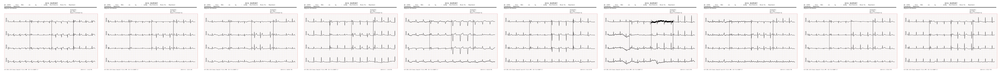

In [9]:
print("")
print("TRAINING DATA FOR Normal:")
print("")
images_details(Normal)
print("")
plot_images(Normal, 10)

In [10]:
train_datagen=ImageDataGenerator(rescale=1./255,shear_range=0.2,zoom_range=0.2,horizontal_flip=True)
training_set=train_datagen.flow_from_directory('DATASET/TRAIN',target_size=(224,224),batch_size=32,class_mode='categorical')

Found 5000 images belonging to 5 classes.


In [11]:
test_datagen=ImageDataGenerator(rescale=1./255)
test_set=test_datagen.flow_from_directory('DATASET/TEST',target_size=(224,224),batch_size=32,class_mode='categorical')

Found 1000 images belonging to 5 classes.


In [12]:
Classifier=Sequential()
Classifier.add(Convolution2D(32,(3,3),input_shape=(224,224,3),activation='relu'))
Classifier.add(MaxPooling2D(pool_size=(2,2)))
Classifier.add(Flatten())
Classifier.add(Dense(38, activation='relu'))
Classifier.add(Dense(5, activation='softmax'))
Classifier.compile(optimizer='rmsprop',loss='categorical_crossentropy',metrics=['accuracy'])

In [13]:
model_path = "MANUAL.h5"

callbacks = [
    ModelCheckpoint(model_path, monitor='accuracy', verbose=1, save_best_only=True)
]

In [14]:
epochs = 10
batch_size = 512

In [15]:
#### Fitting the model
history = Classifier.fit(
           training_set, steps_per_epoch=training_set.samples // batch_size, 
           epochs=epochs, 
           validation_data=test_set,validation_steps=test_set.samples // batch_size,
           callbacks=callbacks)

Epoch 1/10
9/9 [==============================] - ETA: 0s - loss: 35.7986 - accuracy: 0.1979
Epoch 1: accuracy improved from -inf to 0.19792, saving model to MANUAL.h5
9/9 [==============================] - 17s 2s/step - loss: 35.7986 - accuracy: 0.1979 - val_loss: 4.1286 - val_accuracy: 0.0938
Epoch 2/10
9/9 [==============================] - ETA: 0s - loss: 2.5104 - accuracy: 0.2118
Epoch 2: accuracy improved from 0.19792 to 0.21181, saving model to MANUAL.h5
9/9 [==============================] - 15s 2s/step - loss: 2.5104 - accuracy: 0.2118 - val_loss: 1.7027 - val_accuracy: 0.2500
Epoch 3/10
9/9 [==============================] - ETA: 0s - loss: 3.7101 - accuracy: 0.2538
Epoch 3: accuracy improved from 0.21181 to 0.25379, saving model to MANUAL.h5
9/9 [==============================] - 15s 2s/step - loss: 3.7101 - accuracy: 0.2538 - val_loss: 2.1491 - val_accuracy: 0.1875
Epoch 4/10
9/9 [==============================] - ETA: 0s - loss: 1.6159 - accuracy: 0.1818
Epoch 4: accuracy 

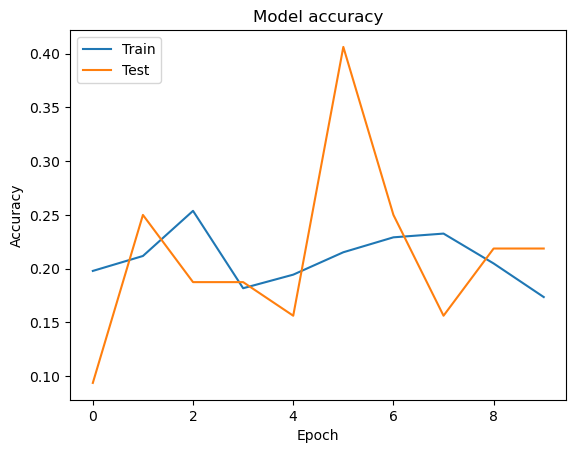

In [16]:
import matplotlib.pyplot as plt

def graph():
    #Plot training & validation accuracy values
    plt.plot(history.history['accuracy'])
    plt.plot(history.history['val_accuracy'])
    plt.title('Model accuracy')
    plt.ylabel('Accuracy')
    plt.xlabel('Epoch')
    plt.legend(['Train', 'Test'], loc='upper left')
    plt.show()

graph()

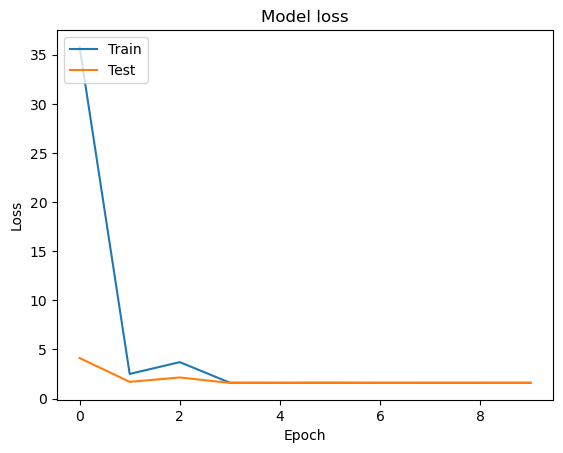

In [17]:
import matplotlib.pyplot as plt

def graph():
    plt.plot(history.history['loss'])
    plt.plot(history.history['val_loss'])
    plt.title('Model loss')
    plt.ylabel('Loss')
    plt.xlabel('Epoch')
    plt.legend(['Train', 'Test'], loc='upper left')
    plt.show()
graph()